# Lab 3: Image Classification

Image classification is a computer vision technique to categorize an image based using its visual content. The approches include:  

1. Classiscal approach: task-based manual feature extarction and perform classification using machine leaning classifiers like support vector machine, random forest etc.  

2. Deep learning approach: Training a convolutional neural networks (CNN) models like Resnet, YOLO, ViT etc.

## Traffic Light Color Detection

In this lab we will do traffic light color detection which is crucial for autonomous driving. Recognizing traffic light colors—red, yellow, and green—is essential for making real-time decisions such as stopping, slowing down, or proceeding.


In this lab, we will do trafiic light color detection using the dataset curated for Udacity course on *Intro To Self Driving Cars*. 

<img title="a title" alt="Alt text" src="traffic_light_color_sample.png" width="200" height="300">


*All images come from MIT self-driving car course and are licensed under a Creative Commons Attribution-ShareAlike 4.0 International License.*

### Tasks
Implement and test two classifiers:
1. A simple classical that uses classic computer vision techniques.
2. Training a CNN like ResNet, YOLO, ViT etc of your choice using Pytorch.

### Objective: 
1. Get classification accuracy of >90% on test dataset.
2. Avoid incorrect classification of Red light as Green light

### Outcome
1. Classical Approach:
    - Short description of the approach used for detecting traffic light color.
    - How did you decide the thresholds if done manually? How did you create the feature vector if using SVM or random forest classifiers?
    - Function to detect traffic light color.
    ```
    def trafficColorDetection(image:np.ndarray)->str:
        '''
        function to detect traffic light color.
        
        image: color image
        ___
        color: string of the detected color: 'Red', 'Green', 'Yellow'
        '''
        ...
    ```
    - Confusion matrix and the accuracy on the test dataset.
    - An overview of the results. Do you think the accuracy you get is satisfactory. Any suggstions to improve the results further.


2. Deep Learning Approach:
    - Short description related of the approch used for training the deep learning model.
        - CNN model used
        - Image augmentations
        - Image size used for training and testing. Are they different?
        - Selection of optimizer, number of epochs, batch size
        - Loss function
        
    - Show the training plots (training loss, testing loss, testing accuracy). Do you think the training was good just looking at the plots.
    - Confusion matrix and the accuracy on the test dataset using the best trained model.
    - An overview of the results. Do you think the accuracy you get is satisfactory. Any suggstions to improve the results further.

### Useful Modules

Data loading: *[torchvision.datasets.ImageFolder](https://pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html)*

Classification Report: *[sklearn.metrics.classification_report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)*

Confusion Metrics: *[sklearn.metrics.confusion_matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)*

Deep Learning Model: *[torch.hub.load](https://pytorch.org/vision/main/models.html)*

Image Augmentations: *[torchvision.transforms.v2](https://pytorch.org/vision/main/transforms.html)*


# 3.1 Classical Approach

**Add method description Here**

### Steps:
1. Create the fucntion *trafficColorDetection*.
2. Load dataset and fine tune model on train dataset only.
3. Generate accuracy report and visualize confusion matrix.

In [93]:
import cv2
import numpy as np


def trafficColorDetection(image:np.ndarray)->str:
    '''
    function to detect traffic light color.
    
    image: color image
    ___
    color: string of the detected color: 'Red', 'Green', 'Yellow'
    '''
    # Example implementation using simple color thresholding
    # Convert image to HSV color space
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    
    # Define color ranges for red, green, and yellow
    red_lower = np.array([0, 100, 100])
    red_upper = np.array([10, 255, 255])
    green_lower = np.array([50, 100, 100])
    green_upper = np.array([70, 255, 255])
    yellow_lower = np.array([20, 100, 100])
    yellow_upper = np.array([30, 255, 255])
    
    # Create masks for each color
    red_mask = cv2.inRange(hsv, red_lower, red_upper)
    green_mask = cv2.inRange(hsv, green_lower, green_upper)
    yellow_mask = cv2.inRange(hsv, yellow_lower, yellow_upper)
    
    # Count the number of pixels for each color
    red_count = cv2.countNonZero(red_mask)
    green_count = cv2.countNonZero(green_mask)
    yellow_count = cv2.countNonZero(yellow_mask)
    
    # Determine the color with the most pixels
    if red_count > green_count and red_count > yellow_count:
        return 'red'
    elif green_count > red_count and green_count > yellow_count:
        return 'green'
    elif yellow_count > red_count and yellow_count > green_count:
        return 'yellow'
    else:
        return 'red' # default to red if no color is detected
    

In [94]:
# Data Loading: Load train and test images seperately

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Define transforms for training and testing
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Load datasets
train_dataset = datasets.ImageFolder(root='Traffic_Light_Images/training', transform=train_transform)
test_dataset = datasets.ImageFolder(root='Traffic_Light_Images/test', transform=test_transform)

# Dataloaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Fine tuning parameters/threshold depending for classical approach using train dataset
# Done by playing with color ranges trafficColorDetection

In [95]:
# Traffic signal detection on the test dataset after finalizing the parameters/thresholds

y_true = []
y_pred = []

# Ensure the dataset labels match ['Red', 'Green', 'Yellow']
assert set(test_dataset.classes) == {'red', 'green', 'yellow'}, \
    f"Dataset classes must be ['Red', 'Green', 'Yellow'], found {test_dataset.classes}"

for image, label in test_dataset:
    # Convert tensor to numpy array and denormalize
    image_np = (image.numpy().transpose(1, 2, 0) * 255).astype(np.uint8)
    y_true.append(test_dataset.classes[label])  # Append class name from dataset
    y_pred.append(trafficColorDetection(image_np))  # Predict using the function



# Generate Accuracy report on test dataset

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Classification report
print(classification_report(y_true, y_pred, target_names=['red', 'green', 'yellow']))
print(accuracy_score(y_true, y_pred))

# Generate confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred, labels=['red', 'green', 'yellow'])

              precision    recall  f1-score   support

         red       0.21      0.07      0.10       107
       green       0.70      0.21      0.32       181
      yellow       0.01      0.33      0.03         9

    accuracy                           0.16       297
   macro avg       0.31      0.20      0.15       297
weighted avg       0.50      0.16      0.23       297

0.16161616161616163


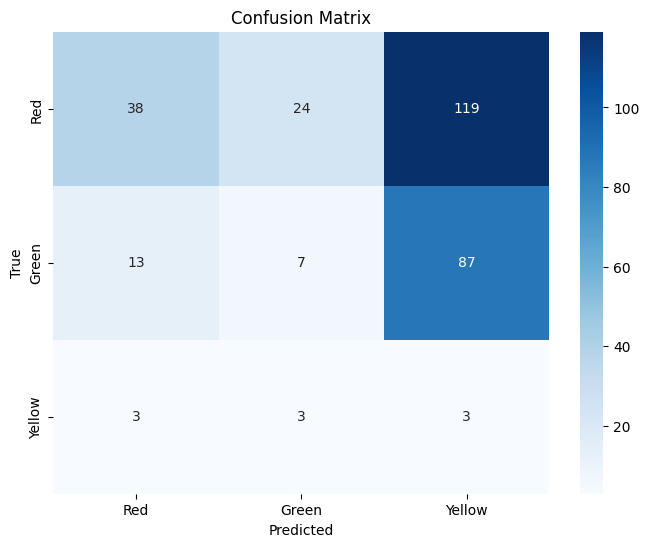

In [96]:
# Visualize confusion matrix on test dataset

import matplotlib.pyplot as plt
import seaborn as sns

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Red', 'Green', 'Yellow'], 
            yticklabels=['Red', 'Green', 'Yellow'])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

<span style="color:Red">Q1</span>. Do you think the accuracy you get is satisfactory. 

<span style="color:Red">Q2</span>. Any suggstions to improve the results further (Please don't put use deep learning methods).

<span style="color:Red">Q1</span>: I only get a accuracy of 16%, it is not satisfactory. Color distortions in poor lighting or other artifacts may degrade performance. In the confusion matrix we can see that most predictions are yellow.

<span style="color:Red">Q1</span>: You could add pre-processing steps like histogram equalization for illumination invariance or use additional features like shape detection for traffic lights.

# 3.2 Deep Learning Approach
**Use Pytorch 2.2 or above**

### Steps:
1. Go over the list of classification models, training and testing image augmentations, optimizer, and loss fucntions avilable in Pytorch. Select the ones you want to try.
2. Load dataset and create dataloaders.
3. Train the model. Decide how to select the best model (high test accuracy, low loss or something)
4. Generate accuracy report and visualize confusion matrix on test dataset.

In [97]:
import torch
import torchvision
from tqdm.auto import tqdm
from torchvision import transforms
from logger import LOGGER, GenericLogger

import time
import torch
import torchvision
from torch import nn, optim
from torchvision import datasets, transforms, models
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [98]:
# Device cpu or cuda
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

# Logger
logger = GenericLogger(save_dir="/path/to/save/model/", console_logger=LOGGER)

TensorBoard: Start with 'tensorboard --logdir \path\to\save', view at http://localhost:6006/


In [99]:
# Select Model and change the 
#model = torch.hub.load()
model = models.resnet18(pretrained=True) 
model.to(device)
print(model)

#change the last layer so the output size is number of classes needed
model.fc = nn.Linear(model.fc.in_features, 3)

c:\Users\zsven\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\zsven\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

<span style="color:Red">Q3</span>. Explain the choice of augmentations, optimizer and loss function used.

In [100]:
# Select batch size
bs = 32#4
image_size = (64, 64) #=(h, w)


# create the train and test augmentations
train_augmentation = transforms.Compose([
    
])

test_augmentation = transforms.Compose([
    
])

train_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

test_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# create train and test dataloader
# images should be normalized
train_dataset = datasets.ImageFolder(root='Traffic_Light_Images/training', transform=train_transform)
test_dataset = datasets.ImageFolder(root='Traffic_Light_Images/test', transform=test_transform)

train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=bs, shuffle=True)
test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=bs, shuffle=False)

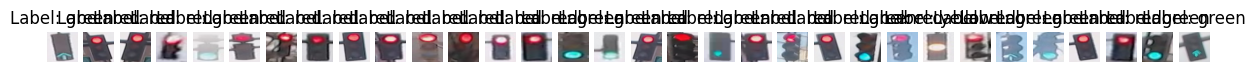

In [101]:
# Visualize the images from dataloader
def visualize_images(dataloader):
    data_iter = iter(dataloader)
    images, labels = next(data_iter)
    fig, axes = plt.subplots(1, len(images), figsize=(15, 5))
    for i, image in enumerate(images):
        axes[i].imshow(image.numpy().transpose(1, 2, 0) * 0.5 + 0.5)  # Denormalize and plot
        axes[i].set_title(f"Label: {train_dataset.classes[labels[i]]}")
        axes[i].axis("off")

visualize_images(train_dataloader)

In [102]:
# assign class name to the model
model.names = train_dataloader.dataset.classes  # attach class names

In [103]:
# Select Optimizer
# need to decide the leraning rate ad other parameters
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Select Loss function
criterion = nn.CrossEntropyLoss() # for multi-class classification

best_fitness = 0.0

In [104]:
# Number of epochs
epochs = 10
t0 = time.time()
TQDM_BAR_FORMAT = '{l_bar}{bar:10}{r_bar}'

from copy import deepcopy
from datetime import datetime

In [106]:
for epoch in range(epochs):  # loop over the dataset multiple times
    tloss, vloss, fitness = 0.0, 0.0, 0.0  # train loss, val loss, fitness
    model.train() #setting model weight for training or activating gradient calculation

    pbar = tqdm(enumerate(train_dataloader), total=len(train_dataloader), bar_format=TQDM_BAR_FORMAT)
    for i, (images, labels) in pbar:  # progress bar
        images, labels = images.to(device, non_blocking=True), labels.to(device)

        # Forward
        loss = criterion(model(images), labels)

        # Backward
        loss.backward()

        # Optimize
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)  # clip gradients
        optimizer.step()
        optimizer.zero_grad()
        
        # Print
        tloss = (tloss * i + loss.item()) / (i + 1)  # update mean losses
        mem = '%.3gG' % (torch.cuda.memory_reserved() / 1E9 if torch.cuda.is_available() else 0)  # (GB)
        pbar.desc = f"{f'{epoch + 1}/{epochs}':>10}{mem:>10}{tloss:>12.3g}" + ' ' * 36

    # Test
    model.eval()
    with torch.no_grad():
        vpred, vtargets = [], [] #, vloss, dt = [], [], 0
        n = len(test_dataloader)
        for images, labels in test_dataloader: #bar
            images, labels = images.to(device, non_blocking=True), labels.to(device)
            y = model(images)
            vpred.append(y.argsort(1, descending=True)[:, 0]) # top1
            vtargets.append(labels)
            if criterion:
                vloss += criterion(y, labels)

            vloss /= n
            pred, targets = torch.cat(vpred), torch.cat(vtargets)
            correct = (targets == pred).float() #correct = (vtargets[:, None] == vpred).float()[:,0]
            top1 = correct.mean().item() #acc.mean().value()
        
            if pbar:
                pbar.desc = f'{pbar.desc[:-36]}{vloss:>12.3g}{top1:>12.3g}'

    fitness = top1  # define fitness as top1 accuracy


    # Log metrics
    # Best fitness
    if fitness > best_fitness:
        best_fitness = fitness

    # Log
    metrics = {
        'train/loss': tloss,
        'test/loss': vloss,
        'metrics/accuracy_top1': top1,
        'lr/0': optimizer.param_groups[0]['lr']}  # learning rate
    logger.log_metrics(metrics, epoch),

    # Save model
    final_epoch = epoch + 1 == epochs
    if True or final_epoch:
        ckpt = {
            'epoch': epoch,
            'best_fitness': best_fitness,
            'model': deepcopy(model).half(), #model.half()
            'date': datetime.now().isoformat()}
        
        last = f'model_last_epoch_{epoch + 1}.pth'
        best = 'model_best.pth'

        # Save last, best and delete
        torch.save(ckpt, last)
        if best_fitness == fitness:
            torch.save(ckpt, best)
        del ckpt

  0%|          | 0/38 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

<span style="color:Red">Q4</span>. Explain the training and test plots. What criteria is used for selecting the best model?

Note: Put the training plots in the notebook.

ValueError: x and y must have same first dimension, but have shapes (10,) and (1,)

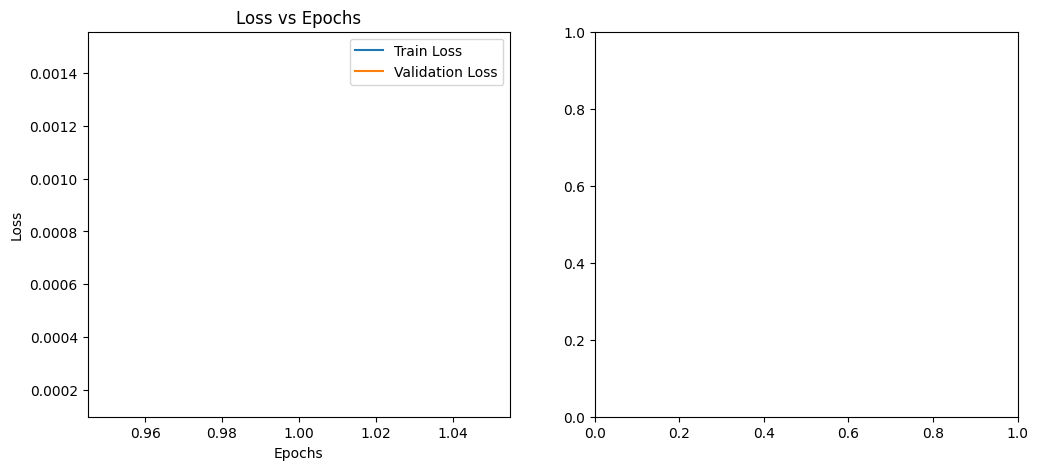

In [109]:
# Training and Test Plots
import matplotlib.pyplot as plt

# Define epochs
epochs_range = range(1, epochs + 1)

# Plot losses
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range[0], tloss, label="Train Loss")
plt.plot(epochs_range[0], vloss, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss vs Epochs")

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range[0], fitness, label="Top-1 Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy vs Epochs")

plt.tight_layout()
plt.show()
